# Prévision du niveau du lac Huron — Séries temporelles

**Auteure :** Ndeye Maimouna Badiane — 4ᵉ année Mathématiques Appliquées et Modélisation, Polytech Lyon
**Langage :** R (packages `tseries` et `forecast`)
**Cadre :** cours de séries temporelles (méthode de Box-Jenkins)

## Objectif

Modéliser l'évolution du **niveau annuel du lac Huron** (un des Grands Lacs d'Amérique du Nord) entre 1875 et 1972, puis **prévoir les années futures**. On compare des modèles simples (lissage de Holt, régression linéaire) à des modèles **ARIMA**, et on évalue leurs prévisions sur des années **jamais vues** par les modèles.

## Les données

La série `LakeHuron` est fournie avec R : **98 valeurs**, une par an (1875 → 1972), en **pieds** (1 pied ≈ 30 cm).

Contrairement à des observations indépendantes, **l'ordre compte** : le niveau d'une année dépend des années précédentes. On ne mélange donc jamais les années, et on teste toujours les modèles sur **les dernières années**.

## Démarche (méthode de Box-Jenkins)

| Étape | Contenu |
|---|---|
| 1 | Description de la série |
| 2 | Test de stationnarité (ADF) |
| 3 | Différenciation |
| 4 | Identification : autocorrélogrammes (ACF, PACF) |
| 5 | Découpage apprentissage / test |
| 6 | Modèles de référence : lissage de Holt, régression linéaire |
| 7 | Estimation des modèles ARIMA et choix par AIC / BIC |
| 8 | Vérification des modèles (coefficients, résidus) |
| 9 | Prévision et comparaison des modèles (RMSE) |

## Étape 1 — Description de la série

**Objectif :** savoir ce que contient la série avant toute analyse (taille, fréquence, valeurs) et repérer à l'œil une tendance, une saisonnalité ou des valeurs aberrantes.

**Le code :** charge la série, affiche le nombre de mesures (`length`), le nombre de mesures par an (`frequency`), les statistiques descriptives (`summary`), puis trace le **chronogramme** (la courbe dans le temps) avec la moyenne en pointillés rouges.

[1] 98

[1] 1

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  576.0   578.1   579.1   579.0   579.9   581.9 

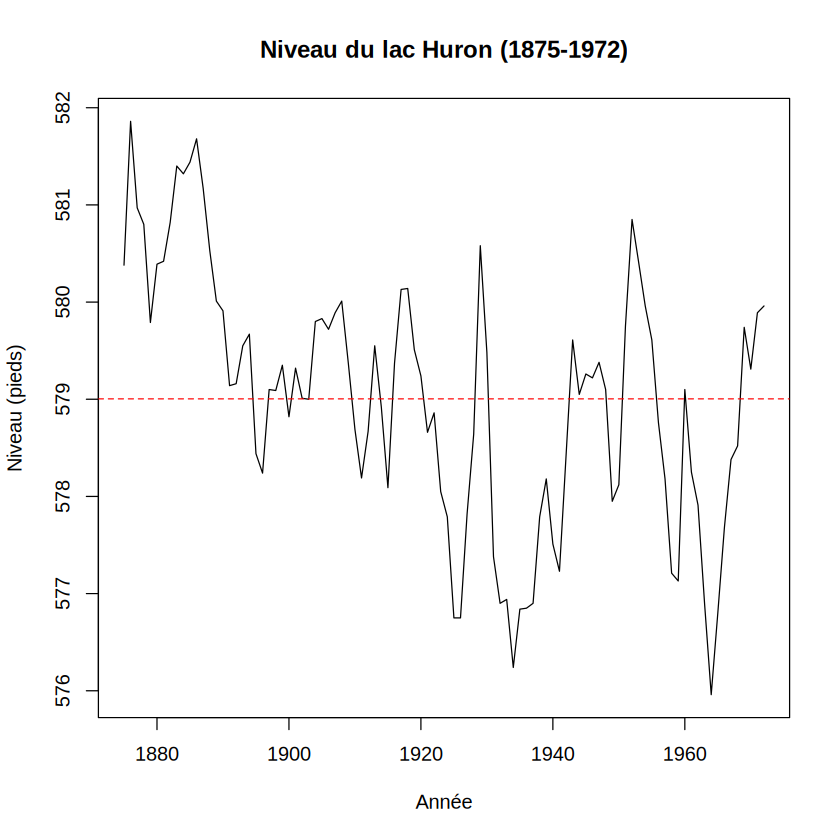

In [1]:
data("LakeHuron")
lh <- LakeHuron
length(lh)
frequency(lh)
summary(lh)

plot(lh, main = "Niveau du lac Huron (1875-1972)",
     xlab = "Année", ylab = "Niveau (pieds)")
abline(h = mean(lh), col = "red", lty = 2)

**Résultats :**
- **98** mesures, **1** par an.
- Niveau entre **576,0** et **581,9** pieds ; moyenne **579,0** ; médiane **579,1**.
- Le chronogramme montre une **tendance à la baisse** (niveau haut vers 1880, creux vers 1930 et 1964) et des **oscillations lentes** : une année haute est souvent suivie d'une autre année haute. La série a de la **mémoire**.

**Ce qu'on retient :**
- **Pas de saisonnalité** : avec une seule mesure par an, on ne peut pas observer de variations à l'intérieur de l'année. Holt-Winters et SARIMA ne sont donc pas adaptés.
- La courbe reste longtemps au-dessus puis en dessous de sa moyenne : c'est un **indice de non-stationnarité**, à vérifier par un test.
- Les variations gardent la même ampleur dans le temps → **modèle additif** (niveau = tendance + partie aléatoire).

## Étape 2 — Test de stationnarité (Dickey-Fuller augmenté)

**Objectif :** vérifier si la série est **stationnaire**, c'est-à-dire si sa moyenne et sa variabilité restent stables dans le temps. Les modèles ARMA en ont besoin : ils apprennent des règles sur le passé qui doivent rester valables dans le futur.

**Le code :** installe et charge `tseries`, puis lance le test ADF.

**Lecture du test :** hypothèse de départ = « la série n'est **pas** stationnaire » (racine unitaire).
- p-value > 0,05 → on ne la rejette pas → **non stationnaire** ;
- p-value < 0,05 → on la rejette → **stationnaire**.

In [2]:
install.packages("tseries")
library(tseries)

adf.test(lh)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘xts’, ‘TTR’, ‘quadprog’, ‘zoo’, ‘quantmod’


Registered S3 method overwritten by 'quantmod':
  method            from
  as.zoo.data.frame zoo 




	Augmented Dickey-Fuller Test

data:  lh
Dickey-Fuller = -2.7796, Lag order = 4, p-value = 0.254
alternative hypothesis: stationary


**Résultat :** statistique de Dickey-Fuller = −2,78, **p-value = 0,254**.

**Ce qu'on retient :** p-value > 0,05, on ne rejette pas l'hypothèse de racine unitaire : **la série n'est pas stationnaire**, à cause de sa tendance. Le test confirme ce que montrait le graphique. Il faut transformer la série avant de la modéliser.

*Attention : absence de saisonnalité et stationnarité sont deux notions différentes. La série n'a pas de saisonnalité, mais elle n'est pas stationnaire à cause de sa tendance.*

## Étape 3 — Différenciation

**Objectif :** rendre la série stationnaire en **retirant la tendance**. Au lieu du niveau, on étudie la **variation d'une année à l'autre** :

$$\nabla X_t = X_t - X_{t-1}$$

C'est le « I » (intégré) de l'ARIMA : le modèle travaille sur les variations, puis revient au niveau pour la prévision.

**Le code :** calcule les différences (`diff`), trace la série différenciée autour de 0, puis refait le test ADF.

[1] 97

Warning message in adf.test(dlh):
“p-value smaller than printed p-value”



	Augmented Dickey-Fuller Test

data:  dlh
Dickey-Fuller = -5.4687, Lag order = 4, p-value = 0.01
alternative hypothesis: stationary


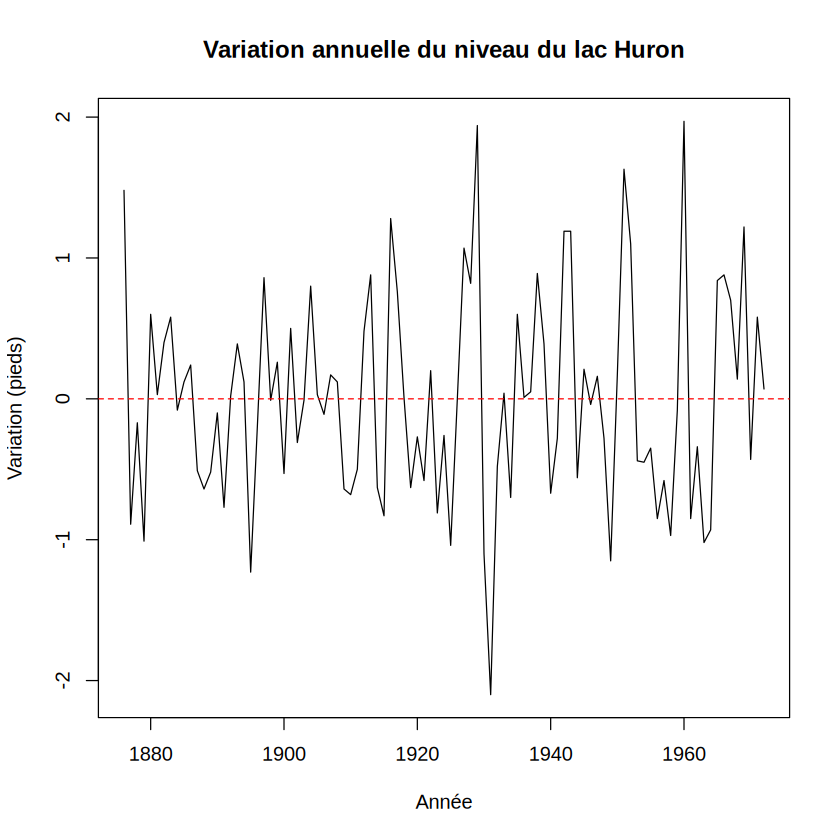

In [3]:
dlh <- diff(lh)
length(dlh)

plot(dlh, main = "Variation annuelle du niveau du lac Huron",
     xlab = "Année", ylab = "Variation (pieds)")
abline(h = 0, col = "red", lty = 2)

adf.test(dlh)

**Résultats :**
- **97** valeurs (1875 n'a pas d'année précédente).
- Le graphique **oscille autour de 0**, entre environ −2 et +2 pieds, sans tendance, en passant souvent au-dessus et en dessous de zéro.
- Test ADF : statistique = −5,47, **p-value < 0,01** (R n'affiche pas de valeur plus petite que 0,01, d'où l'avertissement *« p-value smaller than printed p-value »*).

**Ce qu'on retient :** la série différenciée est **stationnaire**. Une seule différenciation suffit : **d = 1**. Différencier une deuxième fois ajouterait du bruit inutile (sur-différenciation).

## Étape 4 — Identification : autocorrélogrammes (ACF et PACF)

**Objectif :** trouver la forme du modèle ARMA(p, q) à appliquer à la série différenciée.
- **Autocorrélation** : corrélation de la série avec elle-même décalée de *h* années. Elle mesure la **mémoire** de la série.
- **ACF** (autocorrélogramme simple) : lien entre une année et l'année située *h* ans avant, direct ou indirect → donne une piste pour **q** (partie moyenne mobile, MA).
- **PACF** (autocorrélogramme partiel) : lien **direct**, en retirant l'effet des années intermédiaires → donne une piste pour **p** (partie autorégressive, AR).

Une barre qui dépasse les **pointillés bleus** est significative (vrai lien) ; à l'intérieur, elle peut être due au hasard. Sur l'ACF, la barre du décalage 0 vaut toujours 1 et est ignorée.

**Le code :** affiche l'ACF et la PACF côte à côte, pour des décalages de 1 à 20 ans.

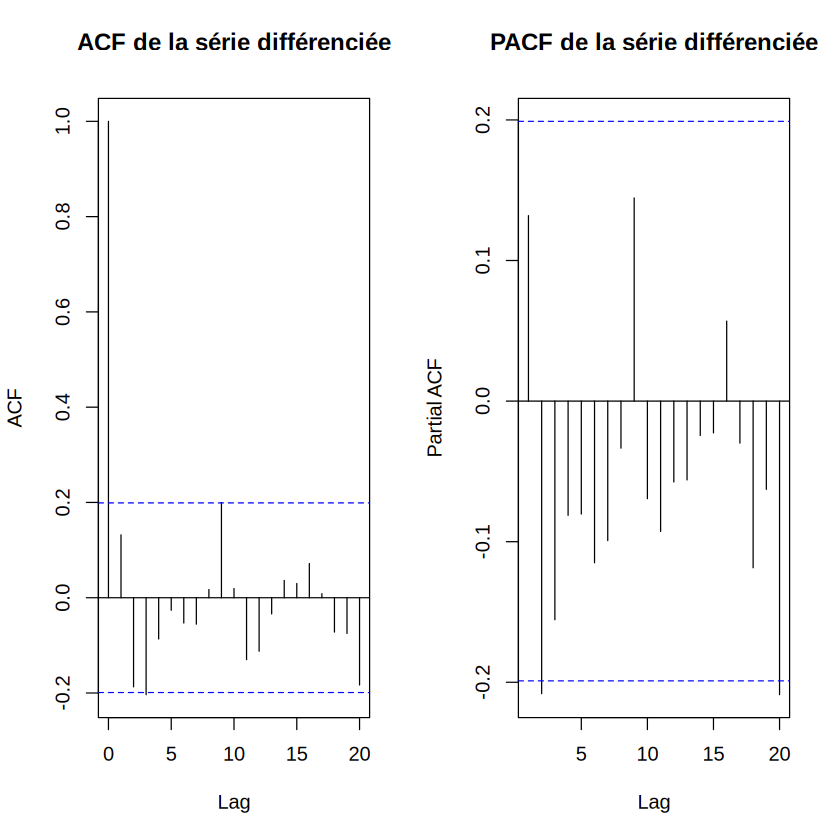

In [4]:
par(mfrow = c(1, 2))
acf(dlh, lag.max = 20, main = "ACF de la série différenciée")
pacf(dlh, lag.max = 20, main = "PACF de la série différenciée")
par(mfrow = c(1, 1))

**Résultats :**
- **ACF :** décalage 1 ≈ +0,13 (non significatif) ; décalages 2 et 3 ≈ −0,20 (à la limite des pointillés) ; tout le reste dans la zone du hasard.
- **PACF :** décalage 1 ≈ +0,13 (non significatif) ; **décalage 2 ≈ −0,21** (dépasse de justesse) ; tout le reste dans la zone du hasard.
- Quelques pics isolés et lointains (décalages 9 et 20) : avec 20 décalages et un seuil à 5 %, environ un dépassement est attendu par hasard. Ils ne sont pas interprétés.

**Ce qu'on retient :** les variations annuelles ont une **mémoire faible**, avec un signal principal au **décalage 2** (piste : petite partie AR d'ordre 2). Les graphiques ne tranchent pas nettement : comme le prévoit la méthode, on retient **plusieurs modèles candidats** (p et q petits, entre 0 et 3), départagés ensuite par l'AIC / BIC.

## Étape 5 — Découpage apprentissage / test

**Objectif :** pour juger un modèle sur sa capacité à **prévoir**, on le teste sur des années qu'il n'a jamais vues (analyse a posteriori). En série temporelle, on ne tire pas les années au hasard : on garde **les dernières**, car on prévoit toujours le futur à partir du passé.

**Le code :** `window` coupe la série en une période d'**apprentissage** (1875–1962) et une période de **test** (1963–1972), puis trace la coupure.

[1] 88

[1] 10

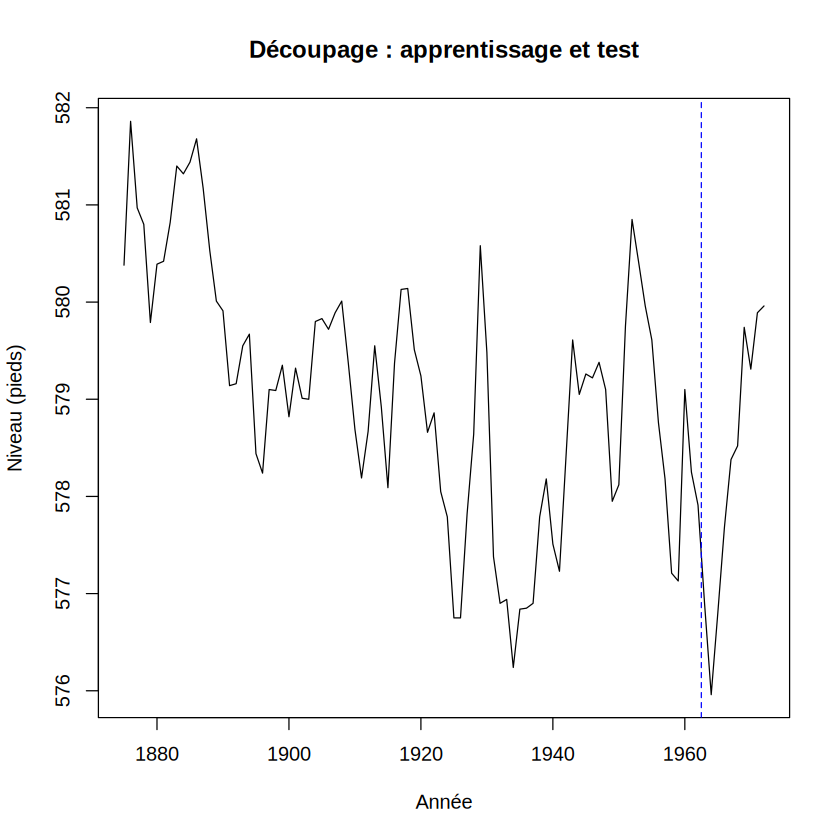

In [5]:
train <- window(lh, end = 1962)
test  <- window(lh, start = 1963)

length(train)
length(test)

plot(lh, main = "Découpage : apprentissage et test",
     xlab = "Année", ylab = "Niveau (pieds)")
abline(v = 1962.5, col = "blue", lty = 2)

**Résultats :** **88** années d'apprentissage et **10** années de test (88 + 10 = 98).

**Ce qu'on retient :** la période de test est **difficile à prévoir** : juste après la coupure, le niveau plonge jusqu'au **minimum historique de 1964 (575,96 pieds)**, puis remonte fortement jusqu'à environ 580 en 1972. Aucun modèle fondé uniquement sur le passé ne peut anticiper un tel « V ». Ce qui compte, c'est quel modèle se trompe **le moins**.

## Étape 6a — Modèle de référence n°1 : lissage de Holt

**Objectif :** construire un modèle simple qui servira de **point de comparaison**. Un modèle plus complexe (ARIMA) ne vaut la peine que s'il fait mieux.

**Principe :** le lissage de Holt estime un **niveau** (moyenne pondérée des valeurs passées, avec plus de poids pour les plus récentes, réglée par α) et une **pente** (réglée par β), puis prolonge : prévision = niveau + pente × horizon. Holt-Winters, qui ajoute une saisonnalité, n'est pas utilisé ici (données annuelles).

**Le code :** installe et charge `forecast`, ajuste Holt sur l'apprentissage, affiche les paramètres estimés et les **10 prévisions** (1963–1972).

In [6]:
install.packages("forecast")
library(forecast)

fit_holt <- holt(train, h = 10)
fit_holt$model$par

pred_holt <- fit_holt$mean
pred_holt

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘colorspace’, ‘fracdiff’, ‘lmtest’, ‘timeDate’, ‘urca’, ‘RcppArmadillo’




alpha          beta             l             b 
 9.969031e-01  1.002103e-04  5.801177e+02 -1.300955e-02

A Time Series:
 [1] 577.8979 577.8848 577.8717 577.8586 577.8454 577.8323 577.8192 577.8061
 [9] 577.7930 577.7799

**Résultats :**
- **α ≈ 0,997** : le niveau suit presque entièrement la dernière année connue.
- **β ≈ 0,0001** : la pente ne se met quasiment jamais à jour ; elle reste à **b ≈ −0,013 pied/an**.
- Prévisions : de **577,90** (1963) à **577,78** (1972), soit une ligne presque plate, légèrement descendante, partant du niveau de 1962 (577,91).

**Ce qu'on retient :** Holt prolonge simplement le dernier niveau avec une légère baisse. Il confirme la **mémoire** de la série (α ≈ 1), mais il **ne peut pas capter les oscillations** : ni le creux de 1964, ni la remontée qui suit.

### Mesure de l'erreur de prévision : le RMSE

**Objectif :** mettre un chiffre sur la qualité d'une prévision, pour comparer les modèles.

$$RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(X_i - \hat{X}_i)^2}$$

On calcule l'erreur de chaque année (réel − prévision), on la met au carré, on fait la moyenne, puis on prend la racine pour revenir en **pieds**. Plus le RMSE est petit, meilleure est la prévision.

**Le code :** crée une fonction `rmse`, réutilisée pour tous les modèles, et l'applique à Holt.

In [7]:
rmse <- function(reel, prev) sqrt(mean((reel - prev)^2))

rmse(test, pred_holt)

[1] 1.475174

**Résultat :** **RMSE de Holt = 1,475 pied** (environ 45 cm d'erreur moyenne sur les 10 années de test).

**Ce qu'on retient :** c'est le **premier point de référence**. Les modèles suivants doivent faire moins que 1,48.

## Étape 6b — Modèle de référence n°2 : régression linéaire

**Objectif :** un second modèle simple, cette fois **déterministe** : la tendance est une formule fixe du temps.

$$X_t = \beta_0 + \beta_1 \, t + \varepsilon_t$$

Les coefficients sont estimés par les **moindres carrés** (la droite qui minimise la somme des erreurs au carré). Pour prévoir, on prolonge la droite.

**Le code :** crée la variable temps (1 à 88 pour l'apprentissage, 89 à 98 pour le test), ajuste la droite avec `lm`, affiche les coefficients, calcule les prévisions et leur RMSE.

In [8]:
t_train <- 1:88
t_test  <- 89:98

fit_lm <- lm(as.numeric(train) ~ t_train)
coef(fit_lm)

pred_lm <- predict(fit_lm, newdata = data.frame(t_train = t_test))
pred_lm

rmse(test, pred_lm)

(Intercept)     t_train 
580.3336599  -0.0281134

1        2        3        4        5        6        7        8 
577.8316 577.8035 577.7753 577.7472 577.7191 577.6910 577.6629 577.6348 
       9       10 
577.6067 577.5785

[1] 1.561103

**Résultats :**
- β₀ (`Intercept`) = **580,33** ; β₁ (pente) = **−0,028 pied/an**, soit une baisse d'environ 2,8 pieds par siècle.
- Prévisions : de **577,83** (1963) à **577,58** (1972), la droite continue de descendre.
- **RMSE = 1,561 pied.**

**Ce qu'on retient :** la régression **confirme la tendance à la baisse**, mais prévoit moins bien que Holt (1,56 contre 1,48) : elle suit la tendance du siècle entier sans tenir compte de la position récente du lac, et elle descend alors que le niveau réel remonte après 1964.

### Visualisation des modèles de référence

**Objectif :** voir sur un même graphique la série réelle, la droite ajustée, et les prévisions de la régression et de Holt.

**Le code :** trace la série (noir), la droite ajustée (bleu), ses prévisions (bleu pointillé), les prévisions de Holt (vert pointillé) et la coupure apprentissage / test (gris).

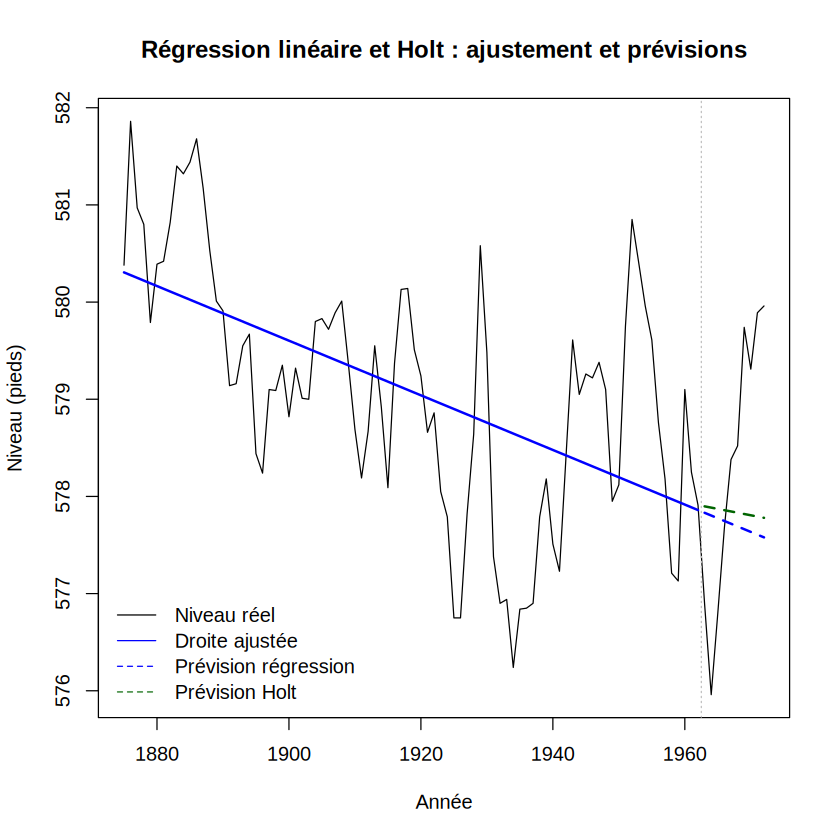

In [9]:
plot(lh, main = "Régression linéaire et Holt : ajustement et prévisions",
     xlab = "Année", ylab = "Niveau (pieds)")

lines(1875:1962, fitted(fit_lm), col = "blue", lwd = 2)
lines(1963:1972, pred_lm, col = "blue", lty = 2, lwd = 2)
lines(pred_holt, col = "darkgreen", lty = 2, lwd = 2)

abline(v = 1962.5, col = "grey", lty = 3)

legend("bottomleft",
       legend = c("Niveau réel", "Droite ajustée", "Prévision régression", "Prévision Holt"),
       col = c("black", "blue", "blue", "darkgreen"),
       lty = c(1, 1, 2, 2), bty = "n")

**Ce qu'on retient :** les deux prévisions sont **presque plates** (autour de 577,5–577,9), alors que le niveau réel plonge en 1964 puis remonte bien au-dessus. Les modèles simples ne reproduisent pas les oscillations de la série.

Même graphique, **zoomé sur 1940–1972**, pour mieux voir la période de test (`xlim`).

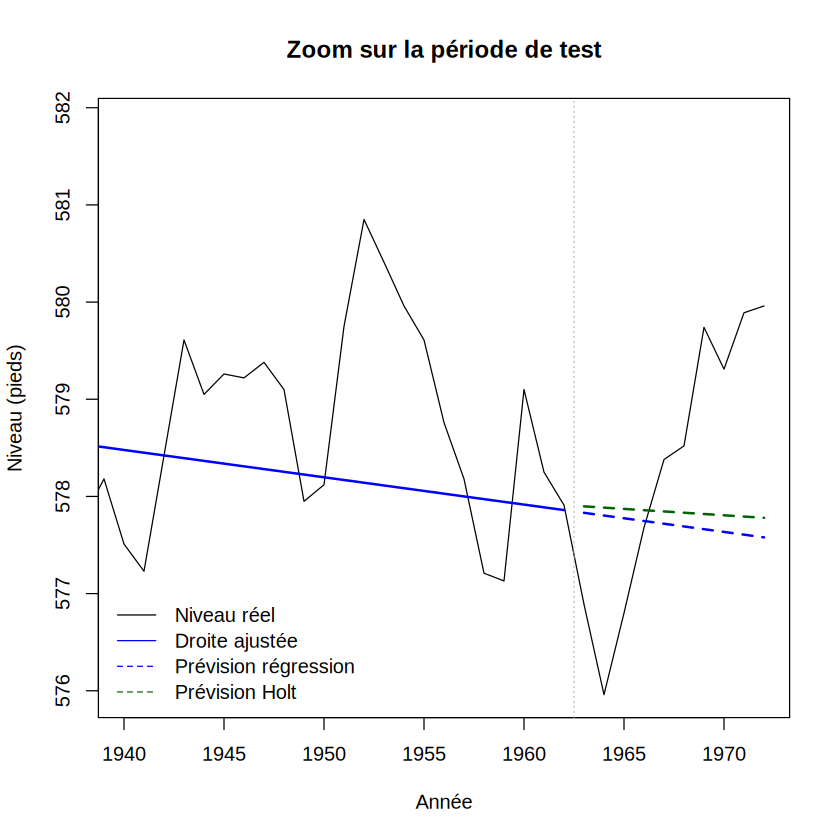

In [10]:
plot(lh, main = "Zoom sur la période de test",
     xlab = "Année", ylab = "Niveau (pieds)",
     xlim = c(1940, 1972))

lines(1875:1962, fitted(fit_lm), col = "blue", lwd = 2)
lines(1963:1972, pred_lm, col = "blue", lty = 2, lwd = 2)
lines(pred_holt, col = "darkgreen", lty = 2, lwd = 2)

abline(v = 1962.5, col = "grey", lty = 3)

legend("bottomleft",
       legend = c("Niveau réel", "Droite ajustée", "Prévision régression", "Prévision Holt"),
       col = c("black", "blue", "blue", "darkgreen"),
       lty = c(1, 1, 2, 2), bty = "n")

**Ce qu'on retient :** le zoom rend l'écart évident : creux de 1964 sous les deux prévisions, puis remontée jusqu'à 580 en 1972, au-dessus des deux prévisions.

## Étape 6c — Les erreurs de la régression sont-elles du hasard ?

**Objectif :** un bon modèle doit laisser des erreurs (résidus) **sans structure**, c'est-à-dire un **bruit blanc**. Si les erreurs se suivent d'une année à l'autre, le modèle a laissé de côté une information prévisible : la mémoire de la série.

**Le code :** récupère les résidus de la droite, les trace, puis applique le **test de Ljung-Box** (test de portmanteau) sur 10 décalages.

**Lecture du test :** hypothèse de départ = « les résidus sont un bruit blanc ».
- p-value > 0,05 → bruit blanc → le modèle a tout capté ;
- p-value < 0,05 → les résidus ont de la mémoire → le modèle est insuffisant.


	Box-Ljung test

data:  res_lm
X-squared = 93.065, df = 10, p-value = 1.332e-15


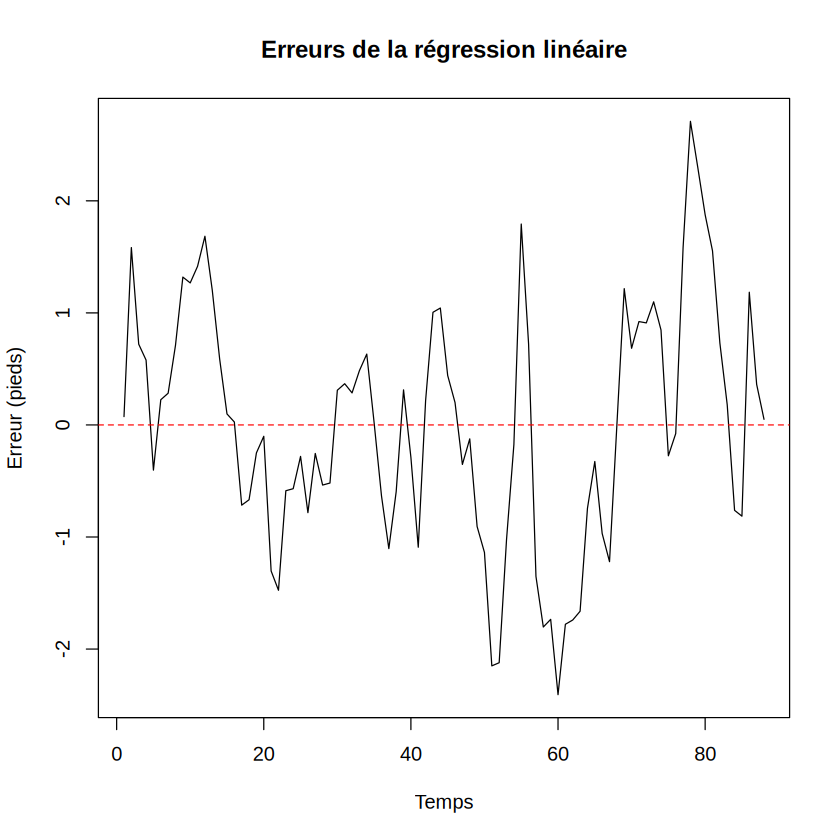

In [11]:
# Étape 6c : vérifier les erreurs de la régression linéaire

# 1. Récupérer les erreurs (résidus) de la droite
res_lm <- residuals(fit_lm)

# 2. Tracer les erreurs au fil du temps
plot(res_lm, type = "l", main = "Erreurs de la régression linéaire",
     xlab = "Temps", ylab = "Erreur (pieds)")
abline(h = 0, col = "red", lty = 2)

# 3. Tester si les erreurs sont un bruit blanc (test de Ljung-Box)
Box.test(res_lm, lag = 10, type = "Ljung-Box")

**Résultats :**
- Le graphique montre de **longues vagues** : erreurs positives pendant une dizaine d'années, puis négatives (jusqu'à −2,4), puis de nouveau positives (jusqu'à +2,7).
- Test de Ljung-Box : statistique = 93,07, **p-value = 1,3 × 10⁻¹⁵** (pratiquement 0).

**Ce qu'on retient :** les résidus sont **fortement autocorrélés**. La régression capte la tendance de fond, mais **pas la dynamique** de la série (quand le lac est haut, il le reste plusieurs années). C'est ce qui justifie le passage à un modèle **ARIMA**, qui utilise les années précédentes pour prévoir.

## Étape 7 — Estimation des modèles ARIMA et choix par AIC / BIC

**Objectif :** l'étape 4 a donné une zone de recherche (p et q petits). On **estime tous les modèles ARIMA(p, 1, q)** avec p et q de 0 à 3 (15 modèles), sur la période d'apprentissage, par **maximum de vraisemblance**, puis on les classe.

**AIC et BIC :** des critères qui récompensent un modèle bien ajusté et **pénalisent la complexité** (le BIC plus fortement). On choisit le modèle qui les **minimise**.

**Le code :** deux boucles parcourent toutes les combinaisons (p, q), estiment chaque modèle avec `Arima`, stockent son AIC et son BIC, puis affichent le tableau trié par AIC croissant. Colonnes : p, q, AIC, BIC.

In [12]:
resultats <- data.frame()

for (p in 0:3) {
  for (q in 0:3) {
    if (p == 0 && q == 0) next
    modele <- Arima(train, order = c(p, 1, q))
    resultats <- rbind(resultats,
                       data.frame(p = p, q = q, AIC = AIC(modele), BIC = BIC(modele)))
  }
}

resultats[order(resultats$AIC), ]

,p,q,AIC,BIC
,<int>,<int>,<dbl>,<dbl>
6,1,2,189.2872,199.1508
9,2,1,189.8798,199.7435
3,0,3,190.0671,199.9308
13,3,1,191.0912,203.4208
7,1,3,191.1100,203.4395
10,2,2,191.1577,203.4873
8,2,0,192.9000,200.2977
2,0,2,193.0061,200.4039
11,2,3,193.0953,207.8908


**Résultats (meilleurs modèles) :**

| Modèle | AIC | BIC |
|---|---|---|
| ARIMA(1,1,2) | **189,29** | **199,15** |
| ARIMA(2,1,1) | 189,88 | 199,74 |
| ARIMA(0,1,3) | 190,07 | 199,93 |

Le moins bon est l'ARIMA(1,1,0) (AIC = 197,79).

**Ce qu'on retient :**
- Les trois premiers sont **pratiquement à égalité** : un écart d'AIC inférieur à 2 n'est pas significatif. Ce sont tous des modèles à **3 coefficients** ; les modèles plus gros sont pénalisés, les plus petits ajustent moins bien.
- C'est cohérent avec des autocorrélogrammes peu nets (étape 4).
- On garde **deux finalistes**, **ARIMA(2,1,1)** (cohérent avec le pic au décalage 2 de la PACF) et **ARIMA(1,1,2)**, à départager par la vérification et la qualité des prévisions.

## Étape 8 — Vérification des deux finalistes

### 8a. Les coefficients sont-ils significatifs ?

**Objectif :** chaque coefficient doit être réellement différent de 0 ; sinon, on peut le retirer et prendre un modèle plus simple. Règle pratique : |coefficient| ≥ 2 × erreur standard (`s.e.`).

**Le code :** estime les deux modèles sur l'apprentissage et affiche leurs coefficients.

In [13]:
m211 <- Arima(train, order = c(2, 1, 1))
m112 <- Arima(train, order = c(1, 1, 2))

m211
m112

Series: train 
ARIMA(2,1,1) 

Coefficients:
         ar1      ar2      ma1
      0.8882  -0.3163  -0.8435
s.e.  0.1548   0.1128   0.1448

sigma^2 = 0.4913:  log likelihood = -90.94
AIC=189.88   AICc=190.37   BIC=199.74

Series: train 
ARIMA(1,1,2) 

Coefficients:
         ar1      ma1      ma2
      0.5517  -0.4885  -0.3775
s.e.  0.1634   0.1654   0.1156

sigma^2 = 0.4876:  log likelihood = -90.64
AIC=189.29   AICc=189.77   BIC=199.15

**Résultats :**

| Modèle | Coefficients (s.e.) | σ² | AIC |
|---|---|---|---|
| ARIMA(2,1,1) | ar1 = 0,888 (0,155) ; ar2 = −0,316 (0,113) ; ma1 = −0,844 (0,145) | 0,491 | 189,88 |
| ARIMA(1,1,2) | ar1 = 0,552 (0,163) ; ma1 = −0,489 (0,165) ; ma2 = −0,378 (0,116) | 0,488 | 189,29 |

**Ce qu'on retient :**
- **Tous les coefficients sont significatifs** (rapports entre 2,8 et 5,8).
- Aucun coefficient AR n'est égal à 1 : la partie AR est stationnaire, une seule différenciation suffisait.
- L'ARIMA(2,1,1) s'écrit, avec $\nabla X_t$ la variation annuelle et $\varepsilon_t$ la « surprise » de l'année :

$$\nabla X_t = 0{,}89\,\nabla X_{t-1} - 0{,}32\,\nabla X_{t-2} + \varepsilon_t - 0{,}84\,\varepsilon_{t-1}$$

Une hausse a tendance à se prolonger l'année suivante, puis à être partiellement corrigée : c'est ce mélange qui produit les **oscillations lentes** de la série.

### 8b. Les résidus sont-ils un bruit blanc ?

**Objectif :** le contrôle le plus important. Le modèle doit avoir capté toute la mémoire de la série : ses résidus doivent être du pur hasard (contrairement à ceux de la régression, étape 6c).

**Le code :** `checkresiduals` affiche, pour chaque modèle, le test de Ljung-Box, la courbe des résidus, leur ACF et leur histogramme.


	Ljung-Box test

data:  Residuals from ARIMA(2,1,1)
Q* = 3.2727, df = 7, p-value = 0.8587

Model df: 3.   Total lags used: 10



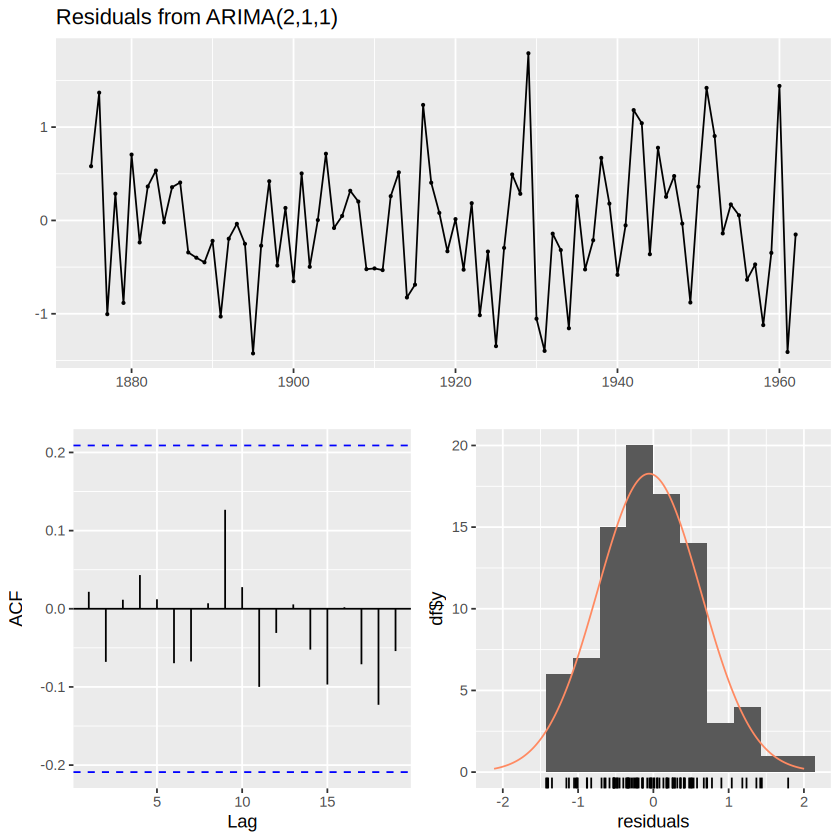


	Ljung-Box test

data:  Residuals from ARIMA(1,1,2)
Q* = 3.0854, df = 7, p-value = 0.877

Model df: 3.   Total lags used: 10



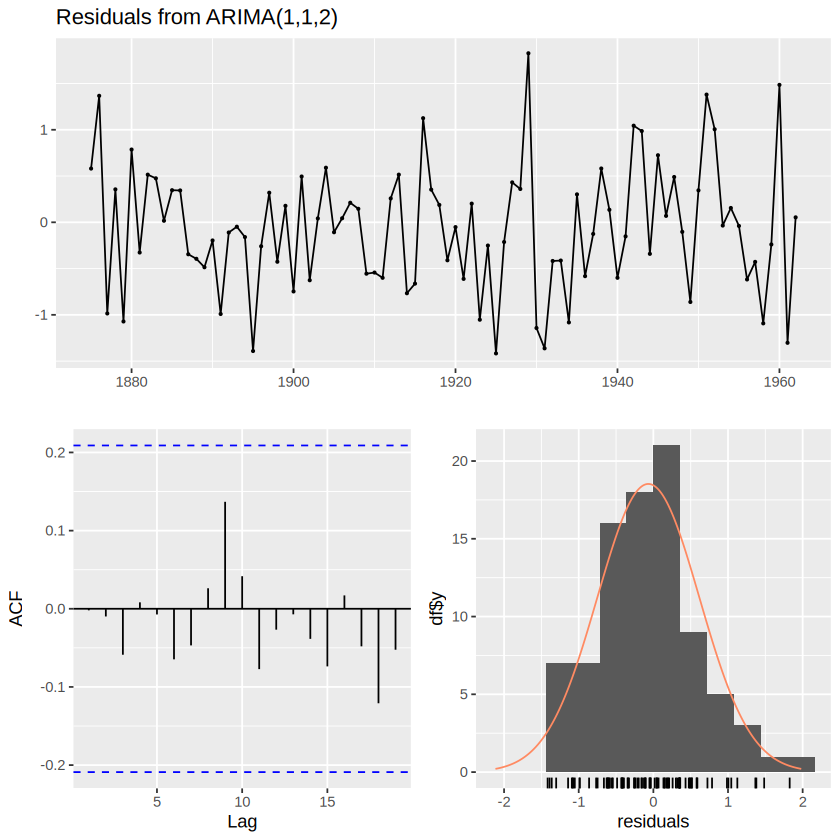

In [14]:
checkresiduals(m211)
checkresiduals(m112)

**Résultats :**

| | ARIMA(2,1,1) | ARIMA(1,1,2) | Régression (rappel) |
|---|---|---|---|
| Statistique de Ljung-Box | 3,27 | 3,09 | 93,07 |
| **p-value** | **0,859** | **0,877** | ≈ 0 |

- Résidus qui varient **au hasard** autour de 0, sans longues vagues.
- ACF des résidus : **toutes les barres dans les pointillés**.
- Histogramme proche d'une **courbe en cloche** (loi normale) : les intervalles de prévision sont fiables.

**Ce qu'on retient :** les résidus des deux ARIMA sont des **bruits blancs**. Les deux modèles ont capté la dynamique de la série et sont **validés** (coefficients significatifs, résidus non corrélés). Ils restent à égalité : on les départage par leurs prévisions.

## Étape 9 — Prévision et comparaison finale

**Objectif :** l'examen final. Chaque ARIMA, estimé sur 1875–1962, prévoit **1963–1972**, et on compare au réel avec le RMSE (pouvoir prédictif).

**Le code :** `forecast` produit les 10 prévisions de chaque modèle (avec leurs intervalles de confiance), puis on calcule leur RMSE.

In [15]:
prev211 <- forecast(m211, h = 10)
prev112 <- forecast(m112, h = 10)

rmse(test, prev211$mean)
rmse(test, prev112$mean)

[1] 1.28799

[1] 1.29717

**Résultats :**

| Rang | Modèle | RMSE sur 1963–1972 (pieds) |
|---|---|---|
| 1 | **ARIMA(2,1,1)** | **1,288** |
| 2 | ARIMA(1,1,2) | 1,297 |
| 3 | Lissage de Holt | 1,475 |
| 4 | Régression linéaire | 1,561 |

**Ce qu'on retient :**
- Les deux ARIMA font nettement mieux que les modèles de référence. L'**ARIMA(2,1,1)** se trompe en moyenne de **1,29 pied**, soit **13 % de moins que Holt** et **17 % de moins que la régression**.
- L'écart entre les deux ARIMA est minime (0,009 pied). On retient l'**ARIMA(2,1,1)** : meilleur RMSE, AIC équivalent (et meilleur sur la série complète), vérification réussie, cohérence avec la PACF.
- Les ARIMA font mieux car ils exploitent la **mémoire** de la série, que Holt et la régression ignorent.

### Visualisation de la prévision de l'ARIMA(2,1,1)

**Le code :** trace la période d'apprentissage, la prévision (bleu) avec ses **intervalles de confiance à 80 % et 95 %** (zones grises), et le vrai niveau sur la période de test (rouge).

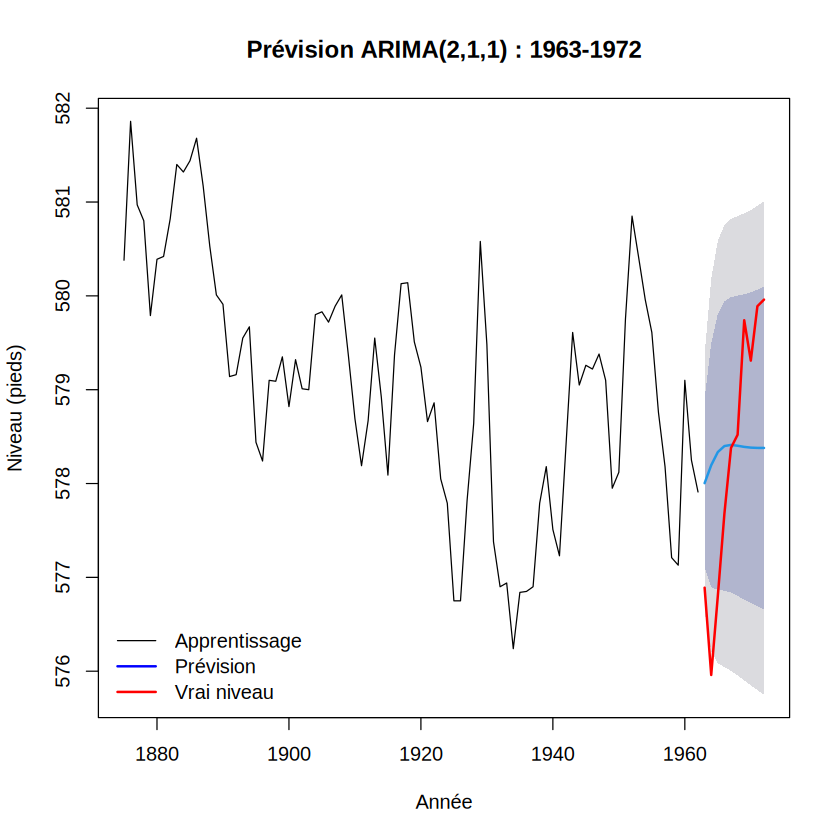

In [16]:
plot(prev211, main = "Prévision ARIMA(2,1,1) : 1963-1972",
     xlab = "Année", ylab = "Niveau (pieds)")
lines(test, col = "red", lwd = 2)

legend("bottomleft",
       legend = c("Apprentissage", "Prévision", "Vrai niveau"),
       col = c("black", "blue", "red"), lty = 1, lwd = c(1, 2, 2), bty = "n")

**Ce qu'on retient :**
- La prévision **remonte légèrement** (≈ 578,0 → 578,4) puis se stabilise : le modèle anticipe un retour vers des niveaux plus habituels après les années basses précédant 1962, alors que Holt et la régression prévoyaient une baisse.
- Les intervalles de confiance **s'élargissent avec l'horizon** : plus on prévoit loin, plus l'incertitude est grande.
- Le vrai niveau plonge en 1964, à la limite basse de l'intervalle à 95 %, puis remonte et reste **globalement dans les intervalles**. Le modèle prévoit la bonne direction, mais pas l'ampleur des mouvements.

## Conclusion

En suivant la méthode de Box-Jenkins :
1. la série, **non stationnaire** (ADF : p = 0,25), a été rendue stationnaire par **une différenciation** (p < 0,01, d = 1) ;
2. les autocorrélogrammes, peu marqués, ont orienté vers de **petits modèles** ;
3. parmi tous les ARIMA(p, 1, q), l'**ARIMA(2,1,1)** a été retenu : AIC parmi les plus faibles, coefficients significatifs, **résidus = bruit blanc** (Ljung-Box : p = 0,86) ;
4. sur les dix dernières années, il obtient le **meilleur RMSE (1,29 pied)**, 13 % de mieux que le lissage de Holt et 17 % de mieux que la régression linéaire, dont les résidus restaient fortement autocorrélés.

## Limites et pistes d'amélioration

- **Peu de données de test** (10 ans) : les résultats dépendent de l'endroit où l'on coupe la série et doivent être interprétés avec prudence.
- **Pas de variables explicatives** : le niveau d'un lac dépend des précipitations, de l'évaporation et des débits. Un modèle **ARMAX** intégrant ces variables exogènes serait plus solide.
- La période de test contient un **événement extrême** (minimum historique de 1964) qu'aucun modèle fondé sur le seul passé ne pouvait anticiper.
- Les prévisions à long terme sont très incertaines, comme le montrent les intervalles de confiance.